# 01 — Data Understanding & Data Quality Audit

**Project:** Sigmoid Bike-Sharing Case Study  
**Dataset:** UCI Bike Sharing Dataset (`hour.csv` and `day.csv`)

This notebook performs the data audit before exploratory analysis and demand forecasting. It uses separate, readable code cells and keeps the familiar variable names `hour_df`, `day_df`, `hour_work`, and `day_work`.

**Audit principles**
- Never replace an absent timestamp with zero rentals automatically.
- Never remove high-demand observations only because they are statistical outliers.
- Flag suspicious sensor values and document decisions before changing them.
- Keep raw data unchanged; perform checks on working copies.

## 1. Import libraries

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Locate the project folder and load the datasets

The notebook searches the current folder and its parents, checks common project locations, and finally opens a folder picker if needed. Select the **main `Sigmoid_Bike_Sharing_Case_Study` folder**, which contains the `data` folder.

In [2]:
def find_project_folder():
    # Search the current working directory and its parent folders.
    search_locations = [Path.cwd(), *Path.cwd().parents]

    for location in search_locations:
        possible_folders = [
            location,
            location / "Sigmoid_Bike_Sharing_Case_Study"
        ]

        for folder in possible_folders:
            hour_file = folder / "data" / "hour.csv"
            day_file = folder / "data" / "day.csv"

            if hour_file.is_file() and day_file.is_file():
                return folder

    # Check common Windows locations.
    common_locations = [
        Path.home() / "Documents" / "Sigmoid_Bike_Sharing_Case_Study",
        Path.home() / "Downloads" / "Sigmoid_Bike_Sharing_Case_Study",
        Path.home() / "Desktop" / "Sigmoid_Bike_Sharing_Case_Study"
    ]

    for folder in common_locations:
        if (
            (folder / "data" / "hour.csv").is_file()
            and (folder / "data" / "day.csv").is_file()
        ):
            return folder

    # Ask the user to select the project folder.
    try:
        import tkinter as tk
        from tkinter import filedialog

        root = tk.Tk()
        root.withdraw()
        root.attributes("-topmost", True)

        selected_folder = filedialog.askdirectory(
            title="Select the Sigmoid_Bike_Sharing_Case_Study folder"
        )

        root.destroy()

        if selected_folder:
            selected_folder = Path(selected_folder)

            if (
                (selected_folder / "data" / "hour.csv").is_file()
                and (selected_folder / "data" / "day.csv").is_file()
            ):
                return selected_folder

    except Exception as error:
        print("Folder picker could not be opened:", error)

    raise FileNotFoundError(
        "Could not locate data/hour.csv and data/day.csv. "
        "Select the main project folder and check its data folder."
    )

In [3]:
BASE_DIR = find_project_folder()
DATA_DIR = BASE_DIR / "data"

hour_path = DATA_DIR / "hour.csv"
day_path = DATA_DIR / "day.csv"

print("Project folder:", BASE_DIR)
print("Data folder:", DATA_DIR)
print("hour.csv exists:", hour_path.exists())
print("day.csv exists:", day_path.exists())

Project folder: C:\Users\prasa\Documents\Sigmoid_Bike_Sharing_Case_Study
Data folder: C:\Users\prasa\Documents\Sigmoid_Bike_Sharing_Case_Study\data
hour.csv exists: True
day.csv exists: True


In [4]:
hour_raw = pd.read_csv(hour_path)
day_raw = pd.read_csv(day_path)

print("Hourly dataset:", hour_raw.shape)
print("Daily dataset:", day_raw.shape)

display(hour_raw.head())
display(day_raw.head())

Hourly dataset: (17379, 17)
Daily dataset: (731, 16)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


## 3. Initial dataset inspection

In [5]:
print("Hourly dataset columns:")
print(hour_raw.columns.tolist())

Hourly dataset columns:
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


In [6]:
print("Daily dataset columns:")
print(day_raw.columns.tolist())

Daily dataset columns:
['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


In [7]:
hour_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.4 MB


In [8]:
day_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB


In [9]:
display(hour_raw.describe().T)

,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.000000,5017.029500,1.00,4345.5000,8690.0000,13034.5000,17379.0000
season,17379.0,2.501640,1.106918,1.00,2.0000,3.0000,3.0000,4.0000
yr,17379.0,0.502561,0.500008,0.00,0.0000,1.0000,1.0000,1.0000
mnth,17379.0,6.537775,3.438776,1.00,4.0000,7.0000,10.0000,12.0000
hr,17379.0,11.546752,6.914405,0.00,6.0000,12.0000,18.0000,23.0000
holiday,17379.0,0.028770,0.167165,0.00,0.0000,0.0000,0.0000,1.0000
weekday,17379.0,3.003683,2.005771,0.00,1.0000,3.0000,5.0000,6.0000
workingday,17379.0,0.682721,0.465431,0.00,0.0000,1.0000,1.0000,1.0000
weathersit,17379.0,1.425283,0.639357,1.00,1.0000,1.0000,2.0000,4.0000
temp,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000


In [10]:
display(day_raw.describe().T)

,count,mean,std,min,25%,50%,75%,max
instant,731.0,366.000000,211.165812,1.000000,183.500000,366.000000,548.500000,731.000000
season,731.0,2.496580,1.110807,1.000000,2.000000,3.000000,3.000000,4.000000
yr,731.0,0.500684,0.500342,0.000000,0.000000,1.000000,1.000000,1.000000
mnth,731.0,6.519836,3.451913,1.000000,4.000000,7.000000,10.000000,12.000000
holiday,731.0,0.028728,0.167155,0.000000,0.000000,0.000000,0.000000,1.000000
weekday,731.0,2.997264,2.004787,0.000000,1.000000,3.000000,5.000000,6.000000
workingday,731.0,0.683995,0.465233,0.000000,0.000000,1.000000,1.000000,1.000000
weathersit,731.0,1.395349,0.544894,1.000000,1.000000,1.000000,2.000000,3.000000
temp,731.0,0.495385,0.183051,0.059130,0.337083,0.498333,0.655417,0.861667
atemp,731.0,0.474354,0.162961,0.079070,0.337842,0.486733,0.608602,0.840896


## 4. Create working copies and parse dates

The raw DataFrames remain unchanged. All date parsing and subsequent checks use working copies.

In [11]:
hour_df = hour_raw.copy()
day_df = day_raw.copy()

hour_df["dteday"] = pd.to_datetime(hour_df["dteday"], errors="coerce")
day_df["dteday"] = pd.to_datetime(day_df["dteday"], errors="coerce")

assert hour_df["dteday"].notna().all(), "Invalid dates found in hour.csv"
assert day_df["dteday"].notna().all(), "Invalid dates found in day.csv"

print("Hourly date range:", hour_df["dteday"].min(), "to", hour_df["dteday"].max())
print("Daily date range:", day_df["dteday"].min(), "to", day_df["dteday"].max())

Hourly date range: 2011-01-01 00:00:00 to 2012-12-31 00:00:00
Daily date range: 2011-01-01 00:00:00 to 2012-12-31 00:00:00


## 5. Missing values and duplicate records

In [12]:
missing_hourly = pd.DataFrame({
    "Missing_Count": hour_df.isnull().sum(),
    "Missing_Percentage": (hour_df.isnull().mean() * 100).round(3)
})

display(missing_hourly)

,Missing_Count,Missing_Percentage
instant,0,0.0
dteday,0,0.0
season,0,0.0
yr,0,0.0
mnth,0,0.0
hr,0,0.0
holiday,0,0.0
weekday,0,0.0
workingday,0,0.0
weathersit,0,0.0


In [13]:
missing_daily = pd.DataFrame({
    "Missing_Count": day_df.isnull().sum(),
    "Missing_Percentage": (day_df.isnull().mean() * 100).round(3)
})

display(missing_daily)

,Missing_Count,Missing_Percentage
instant,0,0.0
dteday,0,0.0
season,0,0.0
yr,0,0.0
mnth,0,0.0
holiday,0,0.0
weekday,0,0.0
workingday,0,0.0
weathersit,0,0.0
temp,0,0.0


In [14]:
print("Duplicate hourly rows:", hour_df.duplicated().sum())
print("Duplicate daily rows:", day_df.duplicated().sum())

print(
    "Duplicate hourly date-hour keys:",
    hour_df.duplicated(subset=["dteday", "hr"]).sum()
)

print(
    "Duplicate daily date keys:",
    day_df.duplicated(subset=["dteday"]).sum()
)

Duplicate hourly rows: 0
Duplicate daily rows: 0
Duplicate hourly date-hour keys: 0
Duplicate daily date keys: 0


## 6. Missing hourly timestamps

A null-value check only detects empty cells in existing rows. It cannot detect an entire date-hour record that is absent from the CSV. We therefore build the expected date-hour grid and compare it with the observed records.

In [15]:
all_dates = pd.date_range(
    start=hour_df["dteday"].min(),
    end=hour_df["dteday"].max(),
    freq="D"
)

expected_timestamps = pd.MultiIndex.from_product(
    [all_dates, range(24)],
    names=["dteday", "hr"]
)

observed_timestamps = pd.MultiIndex.from_frame(
    hour_df[["dteday", "hr"]]
)

missing_timestamps = expected_timestamps.difference(
    observed_timestamps
).to_frame(index=False)

print("Expected hourly records:", len(expected_timestamps))
print("Observed hourly records:", len(observed_timestamps))
print("Missing hourly timestamps:", len(missing_timestamps))

display(missing_timestamps.head(20))

Expected hourly records: 17544
Observed hourly records: 17379
Missing hourly timestamps: 165


,dteday,hr
0,2011-01-02,5
1,2011-01-03,2
2,2011-01-03,3
3,2011-01-04,3
4,2011-01-05,3
5,2011-01-06,3
6,2011-01-07,3
7,2011-01-11,3
8,2011-01-11,4
9,2011-01-12,3


In [16]:
hours_per_day = (
    hour_df.groupby("dteday")["hr"]
    .nunique()
    .reindex(all_dates, fill_value=0)
)

incomplete_days = hours_per_day[hours_per_day < 24]
complete_dates = hours_per_day[hours_per_day == 24].index

print("Complete days:", len(complete_dates))
print("Incomplete days:", len(incomplete_days))
print("Days with fewer than 20 hours:", (hours_per_day < 20).sum())

display(
    incomplete_days.rename("recorded_hours")
    .sort_values()
    .to_frame()
)

Complete days: 655
Incomplete days: 76
Days with fewer than 20 hours: 8


,recorded_hours
2012-10-29,1
2011-01-27,8
2012-10-30,11
2011-01-18,12
2011-01-26,16
2011-08-28,17
2011-08-27,18
2011-02-22,18
2011-03-10,22
2011-02-28,22


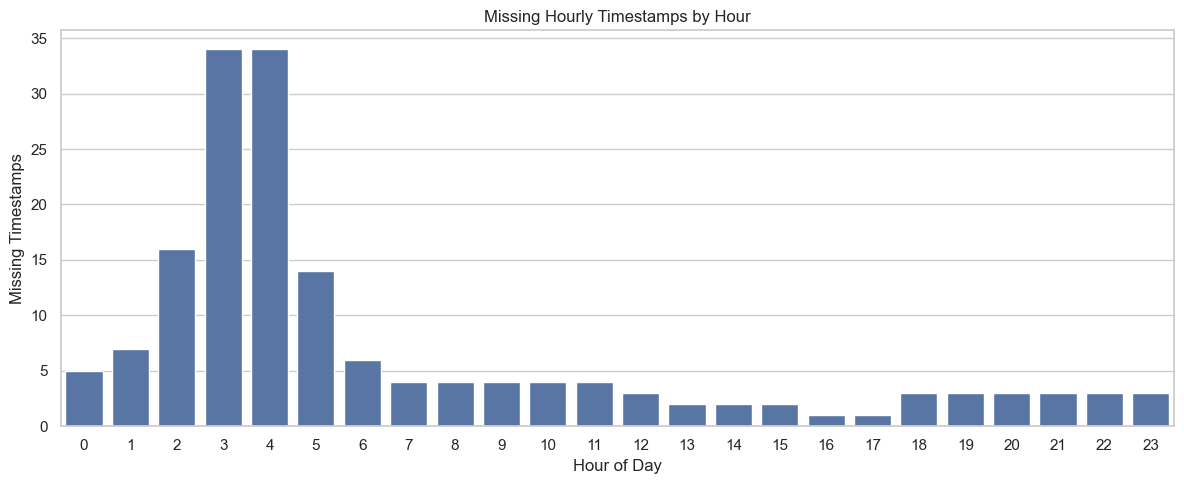

In [17]:
missing_by_hour = (
    missing_timestamps.groupby("hr")
    .size()
    .reindex(range(24), fill_value=0)
    .rename("missing_count")
    .reset_index()
)

plt.figure(figsize=(12, 5))
sns.barplot(data=missing_by_hour, x="hr", y="missing_count")
plt.title("Missing Hourly Timestamps by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Missing Timestamps")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

In [18]:
missing_timestamps["month"] = missing_timestamps["dteday"].dt.month

missing_by_month = (
    missing_timestamps.groupby("month")
    .size()
    .reindex(range(1, 13), fill_value=0)
    .rename("missing_count")
    .reset_index()
)

display(missing_by_month)

,month,missing_count
0,1,59
1,2,27
2,3,15
3,4,3
4,5,0
5,6,0
6,7,0
7,8,13
8,9,3
9,10,37


In [19]:
missing_by_date = (
    missing_timestamps.groupby("dteday")
    .size()
    .sort_values(ascending=False)
    .rename("missing_hours")
    .to_frame()
)

print("Dates with the largest number of missing hours:")
display(missing_by_date.head(20))

Dates with the largest number of missing hours:


,missing_hours
dteday,
2012-10-29,23
2011-01-27,16
2012-10-30,13
2011-01-18,12
2011-01-26,8
2011-08-28,7
2011-08-27,6
2011-02-22,6
2011-02-11,2


In [20]:
# Inspect missing timestamps around October 2012.
october_gaps = missing_timestamps[
    missing_timestamps["dteday"].between(
        "2012-10-01", "2012-10-31"
    )
]

print("Missing timestamps in October 2012:", len(october_gaps))
display(october_gaps)

Missing timestamps in October 2012: 36


,dteday,hr,month
125,2012-10-29,1,10
126,2012-10-29,2,10
127,2012-10-29,3,10
128,2012-10-29,4,10
129,2012-10-29,5,10
130,2012-10-29,6,10
131,2012-10-29,7,10
132,2012-10-29,8,10
133,2012-10-29,9,10
134,2012-10-29,10,10


**Interpretation:** The reference case study reports 165 missing hourly timestamps, including 36 on October 29–30, 2012, during Hurricane Sandy. The cells above independently calculate these figures from your CSV files. Do not assume that every missing timestamp represents zero demand; retain gaps as missing observations.

## 7. Internal consistency checks

In [21]:
hourly_identity = (
    hour_df["cnt"] == hour_df["casual"] + hour_df["registered"]
).all()

daily_identity = (
    day_df["cnt"] == day_df["casual"] + day_df["registered"]
).all()

print("Hourly cnt = casual + registered:", hourly_identity)
print("Daily cnt = casual + registered:", daily_identity)

Hourly cnt = casual + registered: True
Daily cnt = casual + registered: True


In [22]:
# Compare daily totals from hour.csv against day.csv.
hourly_daily_totals = (
    hour_df.groupby("dteday")["cnt"]
    .sum()
    .rename("hourly_cnt")
)

daily_comparison = (
    day_df[["dteday", "cnt"]]
    .merge(
        hourly_daily_totals,
        on="dteday",
        how="left",
        validate="one_to_one"
    )
)

daily_comparison["hourly_cnt"] = daily_comparison["hourly_cnt"].fillna(0)
daily_comparison["difference"] = (
    daily_comparison["cnt"] - daily_comparison["hourly_cnt"]
)

print("Daily dates compared:", len(daily_comparison))
print(
    "Days with mismatched totals:",
    (daily_comparison["difference"] != 0).sum()
)

display(
    daily_comparison[
        daily_comparison["difference"] != 0
    ].head(20)
)

Daily dates compared: 731
Days with mismatched totals: 0


,dteday,cnt,hourly_cnt,difference


**Why compare all dates?** The reference project reports that hourly sums reconcile with `day.csv`. We test every date rather than only complete 24-hour days. This tells us whether missing timestamps correspond to hours with no recorded rentals or whether the daily and hourly totals genuinely disagree.

## 8. Categorical value validation

In [23]:
expected_values = {
    "season": [1, 2, 3, 4],
    "yr": [0, 1],
    "mnth": list(range(1, 13)),
    "hr": list(range(24)),
    "holiday": [0, 1],
    "weekday": list(range(7)),
    "workingday": [0, 1],
    "weathersit": [1, 2, 3, 4]
}

for column, valid_values in expected_values.items():
    invalid_rows = hour_df[
        ~hour_df[column].isin(valid_values)
    ]
    print(f"{column}: {len(invalid_rows)} invalid observations")

season: 0 invalid observations
yr: 0 invalid observations
mnth: 0 invalid observations
hr: 0 invalid observations
holiday: 0 invalid observations
weekday: 0 invalid observations
workingday: 0 invalid observations
weathersit: 0 invalid observations


In [24]:
for column in ["season", "weathersit", "weekday", "workingday"]:
    print(f"\n{column} value counts:")
    display(
        hour_df[column]
        .value_counts(dropna=False)
        .sort_index()
        .to_frame("count")
    )


season value counts:


,count
season,
1,4242
2,4409
3,4496
4,4232



weathersit value counts:


,count
weathersit,
1,11413
2,4544
3,1419
4,3



weekday value counts:


,count
weekday,
0,2502
1,2479
2,2453
3,2475
4,2471
5,2487
6,2512



workingday value counts:


,count
workingday,
0,5514
1,11865


## 9. Verify season codes against observed months

Do not assign season names based only on an assumed mapping. First inspect which calendar months occur under each numeric season code. Then compare the result with the dataset's README/documentation.

In [25]:
season_months = (
    hour_df.groupby("season")["mnth"]
    .agg(lambda values: sorted(values.unique()))
    .to_frame("observed_months")
)

display(season_months)

,observed_months
season,
1,"[1, 2, 3, 12]"
2,"[3, 4, 5, 6]"
3,"[6, 7, 8, 9]"
4,"[9, 10, 11, 12]"


In [26]:
season_month_counts = pd.crosstab(
    hour_df["season"],
    hour_df["mnth"]
)

display(season_month_counts)

mnth,1,2,3,4,5,6,7,8,9,10,11,12
season,,,,,,,,,,,,
1,1429,1341,949,0,0,0,0,0,0,0,0,523
2,0,0,524,1437,1488,960,0,0,0,0,0,0
3,0,0,0,0,0,480,1488,1475,1053,0,0,0
4,0,0,0,0,0,0,0,0,384,1451,1437,960


**Documentation check:** The reference project flags a possible contradiction between season codes and the README. This notebook exposes the observed month mapping so you can verify it against the exact README supplied with your dataset. Do not silently relabel the values until that comparison is confirmed.

## 10. Numeric ranges and sensor-value investigation

In [27]:
numeric_cols = [
    "temp", "atemp", "hum", "windspeed",
    "casual", "registered", "cnt"
]

range_summary = []

for column in numeric_cols:
    range_summary.append({
        "column": column,
        "minimum": hour_df[column].min(),
        "maximum": hour_df[column].max(),
        "negative_count": int((hour_df[column] < 0).sum()),
        "zero_count": int((hour_df[column] == 0).sum()),
        "missing_count": int(hour_df[column].isna().sum())
    })

display(pd.DataFrame(range_summary))

,column,minimum,maximum,negative_count,zero_count,missing_count
0,temp,0.02,1.0000,0,0,0
1,atemp,0.00,1.0000,0,2,0
2,hum,0.00,1.0000,0,22,0
3,windspeed,0.00,0.8507,0,2180,0
4,casual,0.00,367.0000,0,1581,0
5,registered,0.00,886.0000,0,24,0
6,cnt,1.00,977.0000,0,0,0


In [28]:
print("Zero humidity observations:", (hour_df["hum"] == 0).sum())
print("Zero windspeed observations:", (hour_df["windspeed"] == 0).sum())

zero_humidity = hour_df[hour_df["hum"] == 0].copy()
zero_windspeed = hour_df[hour_df["windspeed"] == 0].copy()

display(
    zero_humidity[
        ["dteday", "hr", "hum", "temp", "atemp",
         "windspeed", "weathersit", "cnt"]
    ]
)

Zero humidity observations: 22
Zero windspeed observations: 2180


,dteday,hr,hum,temp,atemp,windspeed,weathersit,cnt
1551,2011-03-10,0,0.0,0.34,0.3182,0.2537,3,3
1552,2011-03-10,1,0.0,0.34,0.3182,0.2537,3,2
1553,2011-03-10,2,0.0,0.34,0.3182,0.2537,3,1
1554,2011-03-10,5,0.0,0.36,0.3485,0.1940,3,3
1555,2011-03-10,6,0.0,0.36,0.3333,0.3284,3,12
1556,2011-03-10,7,0.0,0.38,0.3939,0.2239,3,37
1557,2011-03-10,8,0.0,0.38,0.3939,0.2836,3,44
1558,2011-03-10,9,0.0,0.40,0.4091,0.2239,3,24
1559,2011-03-10,10,0.0,0.40,0.4091,0.1642,3,17
1560,2011-03-10,11,0.0,0.40,0.4091,0.2537,3,11


In [29]:
print("Zero windspeed observations by weather category:")
display(
    zero_windspeed.groupby("weathersit")
    .size()
    .rename("zero_windspeed_count")
    .to_frame()
)

print("Zero windspeed observations by month:")
display(
    zero_windspeed.groupby(zero_windspeed["dteday"].dt.month)
    .size()
    .rename("zero_windspeed_count")
    .to_frame()
)

Zero windspeed observations by weather category:


,zero_windspeed_count
weathersit,
1,1493
2,570
3,117


Zero windspeed observations by month:


,zero_windspeed_count
dteday,
1,139
2,156
3,121
4,108
5,155
6,153
7,190
8,235
9,215


### Weather variable normalization

The UCI dataset stores these weather measurements in normalized form. For interpretability, the commonly documented transformations are:

- `temp` × 41 → temperature in °C
- `atemp` × 50 → feels-like temperature in °C
- `hum` × 100 → relative humidity in %
- `windspeed` × 67 → windspeed in km/h

We create additional columns for interpretation; the original normalized columns remain unchanged.

In [30]:
hour_df["temp_c"] = hour_df["temp"] * 41
hour_df["atemp_c"] = hour_df["atemp"] * 50
hour_df["humidity_pct"] = hour_df["hum"] * 100
hour_df["windspeed_kmh"] = hour_df["windspeed"] * 67

display(
    hour_df[
        ["temp", "temp_c", "atemp", "atemp_c",
         "hum", "humidity_pct", "windspeed", "windspeed_kmh"]
    ].head()
)

,temp,temp_c,atemp,atemp_c,hum,humidity_pct,windspeed,windspeed_kmh
0,0.24,9.84,0.2879,14.395,0.81,81.0,0.0,0.0
1,0.22,9.02,0.2727,13.635,0.80,80.0,0.0,0.0
2,0.22,9.02,0.2727,13.635,0.80,80.0,0.0,0.0
3,0.24,9.84,0.2879,14.395,0.75,75.0,0.0,0.0
4,0.24,9.84,0.2879,14.395,0.75,75.0,0.0,0.0


In [31]:
weather_ranges = hour_df[
    ["temp_c", "atemp_c", "humidity_pct", "windspeed_kmh"]
].describe().T

display(weather_ranges)

,count,mean,std,min,25%,50%,75%,max
temp_c,17379.0,20.376474,7.894801,0.82,13.9400,20.500,27.0600,41.0000
atemp_c,17379.0,23.788755,8.592511,0.00,16.6650,24.240,31.0600,50.0000
humidity_pct,17379.0,62.722884,19.292983,0.00,48.0000,63.000,78.0000,100.0000
windspeed_kmh,17379.0,12.736540,8.196795,0.00,7.0015,12.998,16.9979,56.9969


**Decision note:** The reference documents zero windspeed as a potentially missing-sensor value, while its final report keeps zero humidity/windspeed values unchanged and documents them. We will flag these readings but will not interpolate or overwrite them in this audit. A zero windspeed can also be physically plausible, so it should not automatically be called an error.

## 11. Rare weather category investigation

In [32]:
weather_counts = (
    hour_df["weathersit"]
    .value_counts(dropna=False)
    .sort_index()
    .rename("observations")
    .to_frame()
)

display(weather_counts)

,observations
weathersit,
1,11413
2,4544
3,1419
4,3


In [33]:
weather_4 = hour_df.loc[
    hour_df["weathersit"] == 4,
    ["dteday", "hr", "weathersit", "temp_c",
     "atemp_c", "humidity_pct", "windspeed_kmh", "cnt"]
]

print("Weather category 4 observations:", len(weather_4))
display(weather_4)

Weather category 4 observations: 3


,dteday,hr,weathersit,temp_c,atemp_c,humidity_pct,windspeed_kmh,cnt
585,2011-01-26,16,4,9.02,9.850,93.0,22.0028,36
8854,2012-01-09,18,4,8.20,11.365,86.0,6.0032,164
9123,2012-01-21,1,4,5.74,6.820,86.0,12.9980,23


Weather category 4 has very few observations in the reference dataset (reported as 3). Keep the category visible during the audit. If later analysis combines it with category 3, document that decision and explain the small sample size.

## 12. Demand outlier screening — IQR method

The IQR method flags unusually high or low hourly rental counts. It is a screening method, not proof of a data error.

In [34]:
Q1 = hour_df["cnt"].quantile(0.25)
Q3 = hour_df["cnt"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

iqr_outliers = hour_df[
    (hour_df["cnt"] < lower_bound) |
    (hour_df["cnt"] > upper_bound)
].copy()

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("IQR-flagged observations:", len(iqr_outliers))

Q1: 40.0
Q3: 281.0
IQR: 241.0
Lower bound: -321.5
Upper bound: 642.5
IQR-flagged observations: 505


In [35]:
display(
    iqr_outliers[
        ["dteday", "hr", "weekday", "workingday",
         "weathersit", "cnt"]
    ].sort_values("cnt", ascending=False).head(25)
)

,dteday,hr,weekday,workingday,weathersit,cnt
14773,2012-09-12,18,3,1,1,977
14964,2012-09-20,17,4,1,1,976
14748,2012-09-11,17,2,1,1,970
14725,2012-09-10,18,1,1,1,968
15084,2012-09-25,17,2,1,1,967
15780,2012-10-24,17,3,1,1,963
10622,2012-03-23,17,5,1,2,957
15108,2012-09-26,17,3,1,1,953
15444,2012-10-10,17,3,1,1,948
15588,2012-10-16,17,2,1,1,943


## 13. Contextual outlier screening

Hourly demand naturally differs by hour, year and day type. A high value at 17:00 should not be judged against the same distribution as a low-demand overnight hour. The following check calculates a z-score within each `yr`, `hr`, and `workingday` group, matching the contextual approach described in the reference.

In [36]:
group_cols = ["yr", "hr", "workingday"]

hour_df["group_mean"] = (
    hour_df.groupby(group_cols)["cnt"]
    .transform("mean")
)

hour_df["group_std"] = (
    hour_df.groupby(group_cols)["cnt"]
    .transform("std")
)

hour_df["contextual_zscore"] = (
    (hour_df["cnt"] - hour_df["group_mean"])
    / hour_df["group_std"].replace(0, np.nan)
)

contextual_outliers = hour_df[
    hour_df["contextual_zscore"].abs() > 3
].copy()

print(
    "Observations with |contextual z-score| > 3:",
    len(contextual_outliers)
)

Observations with |contextual z-score| > 3: 71


In [37]:
contextual_outliers["outlier_direction"] = np.where(
    contextual_outliers["contextual_zscore"] > 3,
    "Upward spike",
    "Downward spike"
)

display(
    contextual_outliers[
        ["dteday", "hr", "yr", "workingday", "cnt",
         "contextual_zscore", "outlier_direction"]
    ].sort_values(
        "contextual_zscore",
        key=lambda values: values.abs(),
        ascending=False
    ).head(30)
)

,dteday,hr,yr,workingday,cnt,contextual_zscore,outlier_direction
2811,2011-05-02,1,0,1,114,9.652897,Upward spike
16065,2012-11-07,2,1,1,74,8.948956,Upward spike
16063,2012-11-07,0,1,1,283,8.811390,Upward spike
13462,2012-07-20,3,1,1,36,8.273003,Upward spike
2810,2011-05-02,0,0,1,177,7.863535,Upward spike
5536,2011-08-23,14,0,1,651,7.666837,Upward spike
11186,2012-04-16,7,1,0,387,7.404703,Upward spike
5537,2011-08-23,15,0,1,601,6.413052,Upward spike
14688,2012-09-09,5,1,0,55,6.041118,Upward spike
16064,2012-11-07,1,1,1,92,5.943242,Upward spike


In [38]:
print("Contextual outlier direction:")
display(
    contextual_outliers["outlier_direction"]
    .value_counts()
    .to_frame("count")
)

print("Contextual outliers by date:")
display(
    contextual_outliers.groupby("dteday")
    .size()
    .sort_values(ascending=False)
    .head(20)
    .to_frame("outlier_count")
)

Contextual outlier direction:


,count
outlier_direction,
Upward spike,51
Downward spike,20


Contextual outliers by date:


,outlier_count
dteday,
2012-12-26,6
2011-05-02,5
2012-02-29,4
2012-04-16,4
2011-04-15,3
2012-07-04,3
2012-12-24,3
2012-11-07,3
2011-04-26,2


**Interpretation:** The reference reports 71 contextual outliers using this grouping approach. Your result should be calculated from your own dataset and may differ if the grouping or standard-deviation convention differs. These are candidates for inspection, not rows to delete automatically.

## 14. Create analysis copies for the next notebook

The raw/working audit data is preserved. We create named copies for later exploratory analysis so that subsequent feature engineering does not modify the audit tables.

In [39]:
hour_work = hour_df.copy()
day_work = day_df.copy()

print("hour_work shape:", hour_work.shape)
print("day_work shape:", day_work.shape)

hour_work shape: (17379, 24)
day_work shape: (731, 16)


## 15. Consolidated data-quality summary

In [40]:
data_quality_summary = pd.Series({
    "Hourly records": len(hour_df),
    "Daily records": len(day_df),
    "Hourly null cells": int(hour_df.isna().sum().sum()),
    "Daily null cells": int(day_df.isna().sum().sum()),
    "Duplicate hourly rows": int(hour_df.duplicated().sum()),
    "Duplicate daily rows": int(day_df.duplicated().sum()),
    "Duplicate date-hour keys": int(hour_df.duplicated(["dteday", "hr"]).sum()),
    "Missing hourly timestamps": len(missing_timestamps),
    "Incomplete days": int((hours_per_day < 24).sum()),
    "Days with fewer than 20 hours": int((hours_per_day < 20).sum()),
    "Days with 24 hours": int((hours_per_day == 24).sum()),
    "Zero humidity rows": int((hour_df["hum"] == 0).sum()),
    "Zero windspeed rows": int((hour_df["windspeed"] == 0).sum()),
    "Weather category 4 rows": int((hour_df["weathersit"] == 4).sum()),
    "IQR-flagged demand rows": len(iqr_outliers),
    "Contextual |z-score| > 3 rows": len(contextual_outliers),
    "Hourly target identity holds": bool(hourly_identity),
    "Daily target identity holds": bool(daily_identity),
    "Daily totals reconcile": bool((daily_comparison["difference"] == 0).all())
})

display(data_quality_summary.to_frame("result"))

,result
Hourly records,17379
Daily records,731
Hourly null cells,0
Daily null cells,0
Duplicate hourly rows,0
Duplicate daily rows,0
Duplicate date-hour keys,0
Missing hourly timestamps,165
Incomplete days,76
Days with fewer than 20 hours,8


## 16. Audit decisions and limitations

| Finding | Decision |
|---|---|
| Null cells | Report and investigate; no automatic imputation |
| Missing hourly timestamps | Preserve as gaps; do not fill with zero |
| Incomplete days | Exclude from full-day comparisons where appropriate |
| Hourly/daily total mismatch | Inspect dates and source records before proceeding |
| Zero humidity | Flag and document; do not automatically interpolate |
| Zero windspeed | Flag and document; do not automatically interpolate |
| Weather category 4 | Retain during audit; assess sample size before grouping |
| Season codes | Verify against the dataset README before assigning labels |
| IQR/contextual outliers | Inspect; retain unless independently verified as errors |
| Normalized weather variables | Create converted columns for interpretation; retain originals |

### Important business limitation

This dataset contains completed rentals. It does not contain station-level inventory, bike availability snapshots, failed rental attempts, or origin-destination records. Therefore, it can describe realised demand patterns but cannot directly identify where riders failed to find a bike or prove that a shortage was caused by spatial allocation.

### Next notebook

**`02_exploratory_analysis.ipynb`** — overall demand, hourly patterns, working-day versus non-working-day behaviour, customer segments, weather, seasonality and peak-demand patterns.